# Изучение рынка заведений общественного питания Москвы




Извиняюсь, по какой-то причине отправилась старая, незаконченная версия проекта

### Цели и задачи проекта

<font color='#777778'>Основная цель проекта сделать анализ рынка общественного питания в Москве для определения подходящего инвесторам Заведения.</font>

### Описание данных

<font color='#777778'>В проекте будут использованы данные из двух файлов.

1) Файл /datasets/rest_info.csv содержит информацию о заведениях общественного питания:

- name — название заведения;
- address — адрес заведения;
- district — административный район, в котором находится заведение, например Центральный административный округ;
- category — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- hours — информация о днях и часах работы;
- rating — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- chain — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
0 — заведение не является сетевым;
1 — заведение является сетевым.
- seats — количество посадочных мест.  
    
2) Файл /datasets/rest_price.csv содержит информацию о среднем чеке в заведениях общественного питания:

- price — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- avg_bill — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:
 * «Средний счёт: 1000–1500 ₽»;
 * «Цена чашки капучино: 130–220 ₽»;
 * «Цена бокала пива: 400–600 ₽» и так далее.
- middle_avg_bill — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
 * Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
 * Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
 * Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- middle_coffee_cup — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
 * Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
 * Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
 * Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.</font>

### Содержимое проекта
- Загрузка и знакомство с данными
- Предобработка данных
- Исследовательский анализ данных
- Категоризация данных.

## 1. Загрузка данных и знакомство с ними



In [1]:
!pip install phik==0.11.0

     |████████████████████████████████| 594 kB 2.3 MB/s eta 0:00:01
  Created wheel for phik: filename=phik-0.11.0-py3-none-any.whl size=599734 sha256=c73ecc0d1883d6f21eddb6b4831720b0a0773807e2f0176e371452691cb80d0b
  Stored in directory: /home/jovyan/.cache/pip/wheels/f4/62/e1/886fe092e3a53f783898861c58016ca757fcd0523db7c2cefe
Successfully built phik


In [2]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [3]:
#Загружаем файлы
df_rest_info = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
df_rest_price = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

- Познакомьтесь с данными и изучите общую информацию о них.

In [4]:
#знакомимся с данными файла rest_info
df_rest_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
# общая информация
df_rest_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [6]:
#знакомимся с данными файла rest_price
df_rest_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
# общая информация
df_rest_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


###  
Датасет rest_info соответствует описанию данных.

После первичного анализа данных можно сделать следующие выводы:

- Стиль написания столбцов соответствует стандарту snake case
- В колонках hours и seats есть пропуски.

Датасет rest_price соответствует описанию данных.

После первичного анализа данных можно сделать следующие выводы:

- Стиль написания столбцов соответствует стандарту snake case  
- Во всех столбцах, кроме id, есть пропуски в данных. В middle_coffee_cup аномальное количество пропусков  

Значения в столбцах соответствуют своему описанию, типы данных корректны в обоих датасетах

### Подготовка единого датафрейма

- Объединим данные двух датасетов в один, с которым и продолжим работу.

In [8]:
#объединяем датасеты столбцу id
df = df_rest_info.merge(df_rest_price, on='id', how='left')
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


In [10]:
df.describe()

,rating,chain,seats,middle_avg_bill,middle_coffee_cup
count,8406.000000,8406.000000,4795.000000,3149.000000,535.000000
mean,4.229895,0.381275,108.421689,958.053668,174.721495
std,0.470348,0.485729,122.833396,1009.732845,88.951103
min,1.000000,0.000000,0.000000,0.000000,60.000000
25%,4.100000,0.000000,40.000000,375.000000,124.500000
50%,4.300000,0.000000,75.000000,750.000000,169.000000
75%,4.400000,1.000000,140.000000,1250.000000,225.000000
max,5.000000,1.000000,1288.000000,35000.000000,1568.000000


## 2. Предобработка данных

Подготовьте данные к исследовательскому анализу:

- Изучите корректность типов данных и при необходимости проведите их преобразование.

In [11]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                  int64
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

In [12]:
#преобразуем столбец chain в тип bool
df['chain'] = df['chain'].astype(bool)

In [13]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                   bool
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

In [14]:
#смотрим количество пропусков в каждом столбце
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [15]:
#доля в процентах
df.isna().sum()/df.shape[0]*100

id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64

In [16]:
#заменим пропуски в столбце seats на значение  "-1"
df['seats'] = df['seats'].fillna(-1)

- Проверим данные на явные и неявные дубликаты, например поля с названием и адресом заведения.

In [17]:
df.duplicated().sum()

0

In [18]:
#смотрим встречается ли одни и те же адреса 
df['address'].value_counts()

Москва, проспект Вернадского, 86В           28
Москва, Усачёва улица, 26                   26
Москва, площадь Киевского Вокзала, 2        20
Москва, Ярцевская улица, 19                 20
Москва, Хорошёвское шоссе, 27               16
                                            ..
Москва, проспект Вернадского, 51, стр. 1     1
Москва, Каспийская улица, 28                 1
Москва, Кольцевая линия, метро Таганская     1
Москва, Большая Никитская улица, 13          1
Москва, улица Гиляровского, 39с3             1
Name: address, Length: 5753, dtype: int64

In [19]:
df.duplicated(subset = ['name'], keep = 'last').sum() #Посчитаем дубли в столбце с названием

2792

In [20]:
# удаляю неявные дубли в связке столбцов
df.drop_duplicates(subset = ['address', 'name', 'district'], inplace = True)
df.duplicated(subset=['address', 'name', 'district']).sum()

0

- Для дальнейшей работы создам столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [21]:
df['is_24_7'] = False
df.loc[df['hours'] == 'ежедневно, круглосуточно', 'is_24_7'] = True
df['is_24_7'].fillna(False, inplace=True)  
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   bool   
 8   seats              8406 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
 13  is_24_7            8406 non-null   bool   
dtypes: bool(2), float64(4), object(8)
memory usage: 870.2+ KB
None


---

### Промежуточный вывод



- Был изменен тип данных в столбце chain на более подходящий
- В результате предобработки данных мы выявили пропуски в стобцах: hours(536), seats(3611), price(5091), avg_bill(4590), middle_avg_bill(5257), middle_coffee_cup(7871).  
  - Вместо пропусков в столбце seats мы оставили значение-заглушку(-1) в количестве 3611 ед. (т.к. нам в дальнейшем вряд ли понадобится считать все места во всех заведениях сразу)  
  - Пропуски в остальных столбцах оставили без изменений
- Явных дубликатов выявлено не было, удалены неявные дубликаты в связке столбцов адреса, названия и района
- Также был создан новый столбец с категорией работает ли заведение круглосуточно

## 3. Исследовательский анализ данных
Проведем исследовательский анализ исходных данных.

---

### Задача 1

Исследуем количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

In [22]:
category_counts = df['category'].value_counts()
category_counts

кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

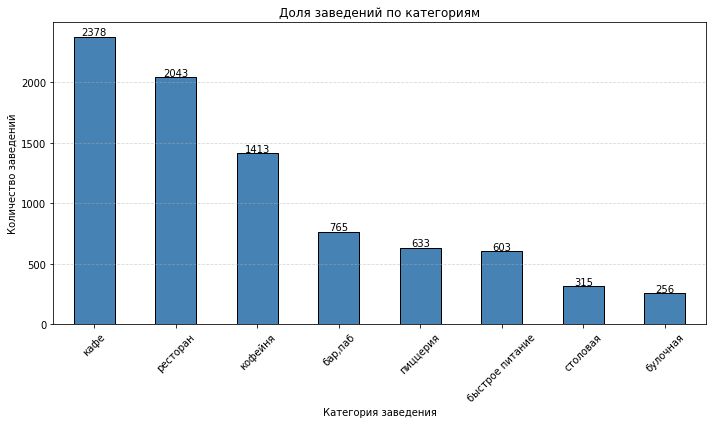

In [23]:
plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Доля заведений по категориям')
plt.xlabel('Категория заведения')
plt.ylabel('Количество заведений')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, count in enumerate(category_counts):
    plt.text(i, count + 10, str(count), ha='center')

plt.tight_layout()


В топ-3 самых распространенных заведений входят кафе, рестораны и кофейни

---

### Задача 2

Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. 

In [24]:
district_counts = df['district'].value_counts()
district_counts

Центральный административный округ         2242
Северный административный округ             900
Южный административный округ                892
Северо-Восточный административный округ     891
Западный административный округ             851
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

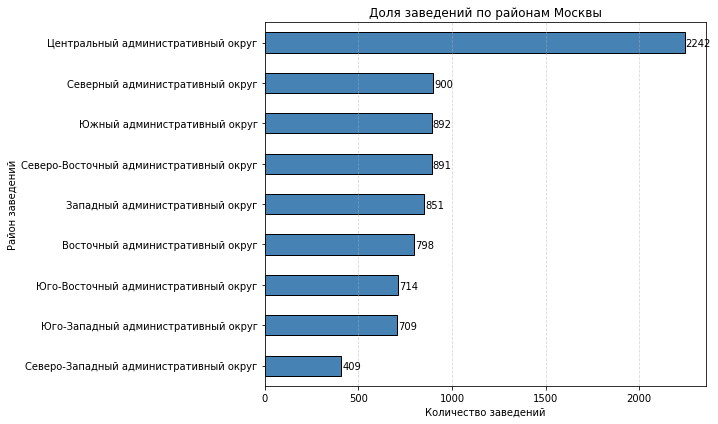

In [25]:
plt.figure(figsize=(10, 6))
district_counts.sort_values().plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Доля заведений по районам Москвы')
plt.xlabel('Количество заведений')
plt.ylabel('Район заведений')
plt.grid(axis='x', linestyle='--', alpha=0.5)

for i, count in enumerate(district_counts.sort_values()):
    plt.text(count + 5, i - 0.1, str(count), color='black')

plt.tight_layout()

In [26]:
central_count = df[(df['district'] == 'Центральный административный округ')]['category'].value_counts()

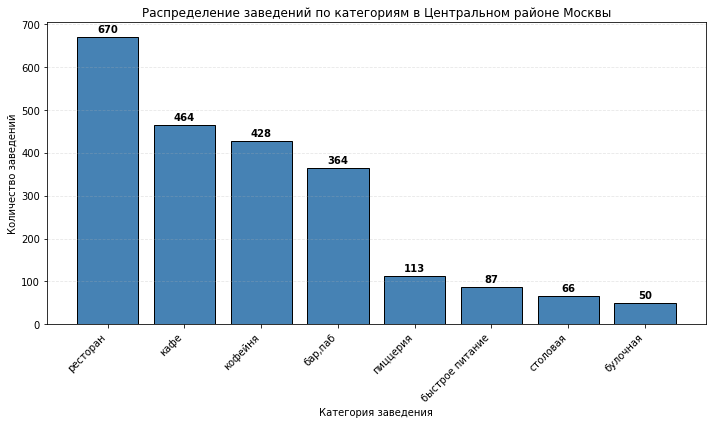

In [27]:
plt.figure(figsize=(10, 6))
bars = plt.bar(central_count.index, central_count, color='steelblue', edgecolor='black', linewidth=1)
plt.title('Распределение заведений по категориям в Центральном районе Москвы')
plt.xlabel('Категория заведения')
plt.ylabel('Количество заведений')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

for i, count in enumerate(central_count):
    plt.text(i, count + max(central_count)*0.01, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


- Большинство заведений расположились в центральном округе, в связи с его востребованностью.
- Преобладающее большинство заведений в ЦАО - рестораны. Это самый  элитный район в Москве, так что неудивительно что именно ресторанов в нем больше всего

---

### Задача 3

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. 

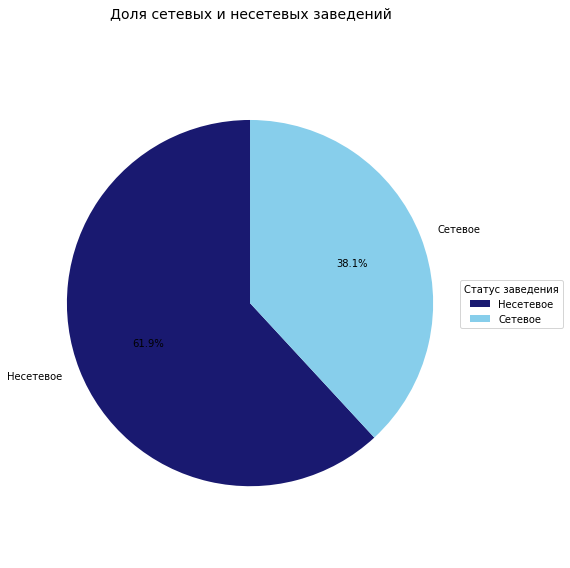

In [28]:
chain_counts = df['chain'].value_counts()

plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    chain_counts,
    autopct='%1.1f%%',
    colors=['midnightblue', 'skyblue'],
    startangle=90,
    labels=['Несетевое', 'Сетевое']  # подписываем сектора
)

plt.title('Доля сетевых и несетевых заведений', fontsize=14, pad=30)
plt.axis('equal')

plt.legend(wedges, ['Несетевое', 'Сетевое'], title="Статус заведения", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

<Figure size 1008x720 with 0 Axes>

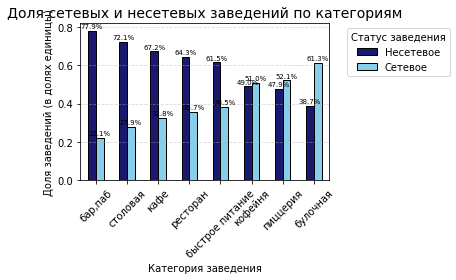

In [29]:
plt.figure(figsize=(14, 10))  

# Вычисляем доли
grouped_category = df.groupby('category')['chain'].value_counts(normalize=True).unstack(fill_value=0)
grouped_category = grouped_category.sort_values(by=0, ascending=False)

# Строим график
ax = grouped_category.plot(kind='bar', rot=45, color=['midnightblue', 'skyblue'], edgecolor='black')

plt.xlabel('Категория заведения')
plt.ylabel('Доля заведений (в долях единицы)')  
plt.title('Доля сетевых и несетевых заведений по категориям', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2., 
        height + grouped_category.max().max() * 0.01, 
        f'{height*100:.1f}%',  
        ha='center', va='bottom', fontsize=7
    )
    
plt.legend(['Несетевое', 'Сетевое'], title="Статус заведения", loc="upper left", bbox_to_anchor=(1.05, 1))


plt.tight_layout()  
plt.show()


Несетевые заведения преобладают. Наибольший разрыв соотношений наблюдается в категориях баров/пабов, столовых, кафе, ресторанов и фастфуде. Наибольшее количество сетевых прослеживаются в кофейнях, пиццериях и булочных.

---

### Задача 4

Исследуем количество посадочных мест в заведениях. Приведнм для каждой категории заведений наиболее типичное для него количество посадочных мест.

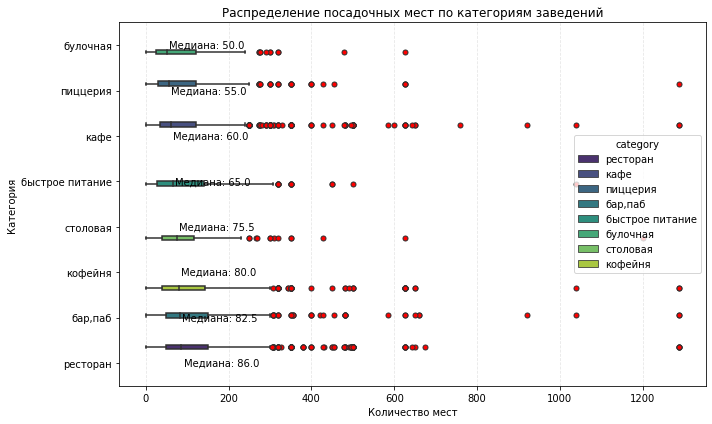

In [30]:
#исключаем заглушки (-1) 
df_filtered = df[(df['seats'] != -1)]
median_values = df_filtered.groupby('category')['seats'].median().sort_values()

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='seats',
    y='category',
    hue='category',
    data=df_filtered,
    order=median_values.index,
    palette='viridis',
    flierprops=dict(marker='o', markersize=5, markerfacecolor='r'),
)

for i, median in enumerate(median_values):
    plt.text(median + 5, i, f'Медиана: {median}', va='center', ha='left', fontsize=10)

plt.title('Распределение посадочных мест по категориям заведений')
plt.xlabel('Количество мест')
plt.ylabel('Категория')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Наибольшее медианное количество мест у ресторанов. Значения сильно превышающие это значение с погрешностью - выброс. В остальном разброс умеренный, если учитывать и те заведения, что работают на вынос

---

### Задача 5

Исследуем рейтинг заведений. 

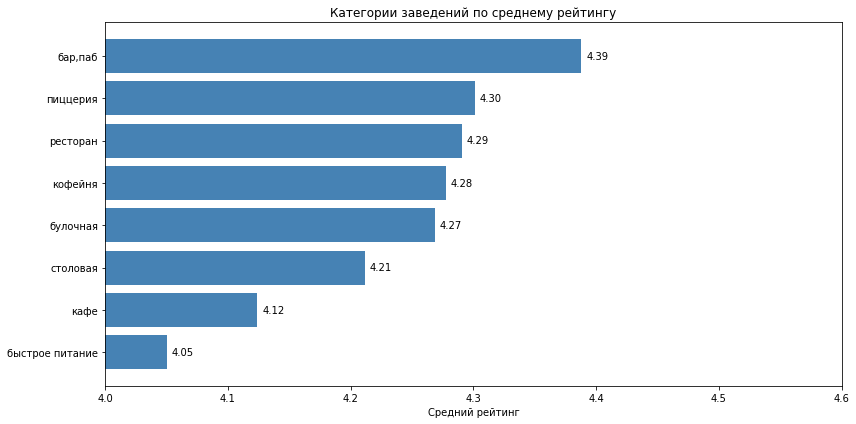

In [31]:

ratings = df.groupby('category')['rating'].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(ratings.index, ratings.values, color='steelblue')

for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{width:.2f}',
                (width, bar.get_y() + bar.get_height() / 2),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=10,
                color='black')

ax.set_title('Категории заведений по среднему рейтингу')
ax.set_xlabel('Средний рейтинг')
ax.set_ylabel('')
plt.xlim(4, 4.6)
plt.tight_layout()
plt.show()


В топ-3 по рейтингу входят бары, пиццерии и рестораны, хотя разброс рейтинга в целом невелик

---

### Задача 6

Изучим с какими данными показывают самую сильную корреляцию рейтинги заведений. Построим и визуализируем матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. 

interval columns not set, guessing: ['rating', 'seats']


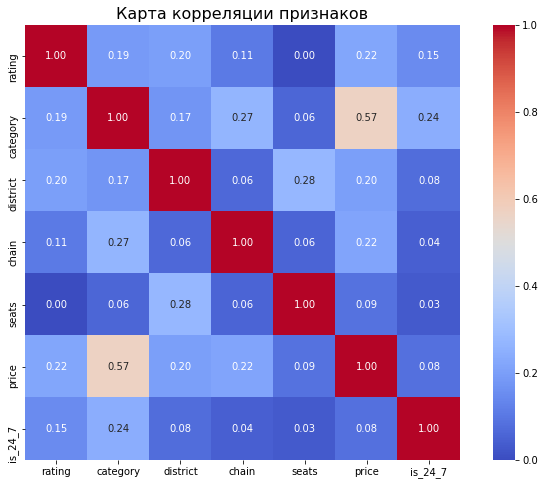

In [32]:
data_subset = df[['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']]

#строим матрицу корреляции 
phik_matrix = data_subset.phik_matrix(interval_cols=None)
plt.figure(figsize=(12, 8))
sns.heatmap(phik_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Карта корреляции признаков', fontsize=16)
plt.show()

Наилучшие результаты на пересечении price и category

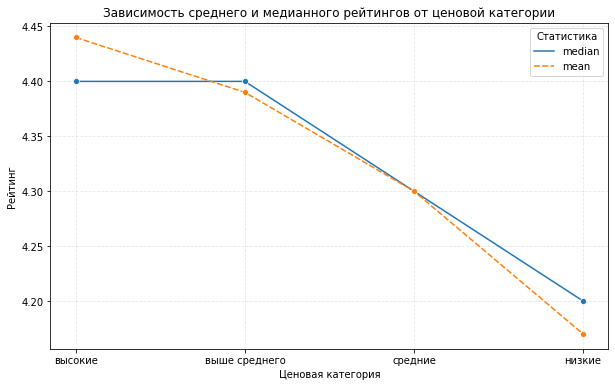

In [33]:
#проверяем зависимость от ценовой категории
link_df = df.groupby('price')['rating'].agg(['median', 'mean']).sort_values(by='mean', ascending=False).round(2)

plt.figure(figsize=(10, 6))
sns.lineplot(data=link_df, marker='o')
plt.title('Зависимость среднего и медианного рейтингов от ценовой категории')
plt.xlabel('Ценовая категория')
plt.ylabel('Рейтинг')
plt.legend(title='Статистика', loc='upper right')
plt.grid(linestyle='--', alpha=0.3)
plt.show()



Цена в значительной степени влияет на выставляемые рейтинги

---

### Задача 7

Сгруппируем данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе.

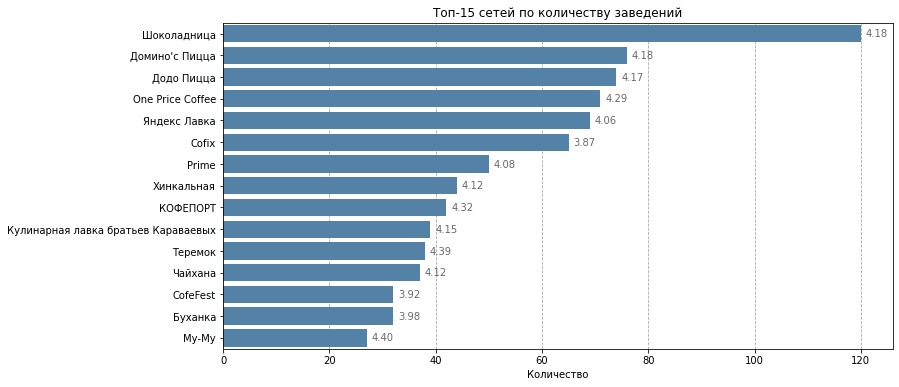

In [34]:
# Выводим топ‑15 сетей
top_chains = (df[df['chain']]
              .groupby('name')
              .agg({'id': 'count', 'rating': 'mean', 'category': 'first'})
              .query('id >= 5')
              .sort_values('id', ascending=False)
              .head(15))

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='id', y=top_chains.index, data=top_chains, color='steelblue')  

for patch in ax.patches:
    name = top_chains.index[int(patch.get_y())]  
    mean_rating = top_chains.loc[name, 'rating']  
    
    
    ax.annotate(f"{mean_rating:.2f}", 
                (patch.get_width(), patch.get_y() + patch.get_height() / 2), 
                xytext=(5, 0), textcoords='offset points',
                ha='left', va='center', fontsize=10, color='dimgrey')

ax.set_axisbelow(True)
ax.grid(axis='x', linestyle='--', color='gray', alpha=0.7)

plt.title('Топ-15 сетей по количеству заведений')
plt.xlabel('Количество')
plt.ylabel('')
plt.xlim(0, top_chains['id'].max() * 1.05)
plt.show()


Самые распространенные сети - кофейни и пиццерии.  
Также отметим, что у сетевых заведений с большим количеством заведений вполне неплохая средняя оценка, связано это с тем, что чем больше количество сетевых точек в разных районах города, тем больше оценок сеть будет собирать по всему городу, и т.к. у сетей зачастую строгий регламент обслуживания, то и оценки в среднем по сети будут примерно одинаковые, что и помогает удержать хороший рейтинг

---

### Задача 8

Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других.


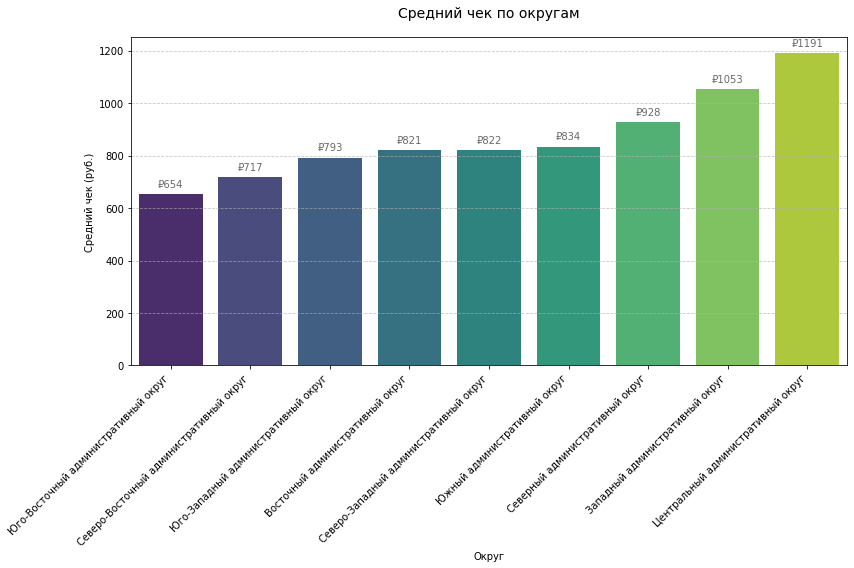

In [35]:
avgbill = df.groupby('district').agg({'middle_avg_bill': 'mean'}).reset_index()
avgbill = avgbill.round(2).sort_values(by = 'middle_avg_bill', ascending = True)
avgbill = avgbill.set_index('district')

plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x=avgbill.index,
    y=avgbill['middle_avg_bill'],
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(f"₽{p.get_height():.0f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom',
                xytext=(0, 5), textcoords='offset points',
                fontsize=10, color='dimgrey')

plt.title('Средний чек по округам', pad=20, fontsize=14)
plt.ylabel('Средний чек (руб.)')
plt.xlabel('Округ')
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Самые высокие средние чеки - в самых востребованных для отдыха районах, в которых наибольшая концентрация премиальных заведений с высоким средним чеком и чем ближе к центру - тем больше таких заведений. Более того - в центральных районах куда больший поток людей, включая туристов, тогда как в отдаленных районах заведениями пользуются зачастую местные жители

---


---

### Промежуточный вывод



Наиболее востребованые заведения в подходящих районах для досуга - центральный и западный.   
Также ценовая категория и рейтинг связаны: заведения с более высокими ценами имеют более высокие оценки.  
В ЦАО много заведений с высокими рейтингами - итог большого количества премиальных востребованных заведений 

Несетевых заведений в Москве больше, чем сетевых.  


## 4. Итоговый вывод и рекомендации



* Мы провели анализ сырых данных, обработали дубликаты, чтобы предоставить инвесторам готовые для анализа данные.

* В ЦАО наибольшая концентрация заведений и высокий средний чек, однако стоит учитывать высокую конкуренцию в каждой категории заведений и дорогую аренду помещений. Однако, судя по анализу рейтинга - аудитория готова платить за удобство и "премиальность", но в то же время для несетевой точки для привлечения клиентуры необходима "уникальность заведения"  
* Сетевые заведения выглядит как стабильное вложение с минимальными рисками, но с меньшими потенциальными доходами. Также не будет проблем с привлечением аудитории, но как замечено выше - меньшие потенциальные доходы, строгий регламент заведения, принадлежащему сети. 
